# Analisis Lanjutan

Visualisasi dari tiga output pipeline (`src/02_rfm.py`, `src/03_cohort.py`,
`src/04_churn_geo.py`): cohort retention, distribusi Segment RFM, dan uji-t
Average Order Value Churned vs Active. Notebook ini cuma memvisualisasikan —
semua angka & keputusan analitis (ambang churn, definisi Segment, dsb.)
sudah dikunci di script `src/`.

In [1]:
"""
Setup: import library & tetapkan palet warna yang dipakai konsisten di
semua chart notebook ini (biru = fokus utama/grup 1, oranye = grup
pembanding/kontras, abu-abu = kategori non-fokus).
"""
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

WARNA_SURFACE = "#fcfcfb"
WARNA_INK_UTAMA = "#0b0b0b"
WARNA_INK_SEKUNDER = "#52514e"
WARNA_INK_MUTED = "#898781"
WARNA_GRID = "#e1e0d9"
WARNA_BASELINE = "#c3c2b7"
WARNA_BIRU = "#2a78d6"
WARNA_ORANYE = "#eb6834"

plt.rcParams.update({
    "figure.facecolor": WARNA_SURFACE,
    "axes.facecolor": WARNA_SURFACE,
    "axes.edgecolor": WARNA_BASELINE,
    "axes.labelcolor": WARNA_INK_SEKUNDER,
    "text.color": WARNA_INK_UTAMA,
    "xtick.color": WARNA_INK_MUTED,
    "ytick.color": WARNA_INK_MUTED,
    "grid.color": WARNA_GRID,
    "axes.grid": False,
    "font.size": 11,
})


## 1. Load output pipeline

In [2]:
PATH_RFM = Path("../output/rfm_table.csv")
PATH_COHORT = Path("../output/cohort_matrix.csv")
PATH_CHURN = Path("../output/churn_summary.csv")

rfm = pd.read_csv(PATH_RFM)
cohort = pd.read_csv(PATH_COHORT, index_col=0)
churn = pd.read_csv(PATH_CHURN)

print(f"rfm_table.csv     : {rfm.shape[0]:,} baris x {rfm.shape[1]} kolom")
print(f"cohort_matrix.csv : {cohort.shape[0]} cohort x {cohort.shape[1]} cohort_index")
print(f"churn_summary.csv : {churn.shape[0]:,} baris x {churn.shape[1]} kolom")
rfm.head()


rfm_table.csv     : 5,861 baris x 10 kolom
cohort_matrix.csv : 25 cohort x 25 cohort_index
churn_summary.csv : 5,861 baris x 4 kolom


,CustomerID,Recency,Frequency,Monetary,R_score,F_score,M_score,RFM_score,Segment,ChurnStatus
0,12346,325,12,77556.46,2,5,5,255,Can't Lose,Churned
1,12347,2,8,4921.53,5,4,5,545,Champions,Active
2,12348,75,5,1658.40,3,4,4,344,Loyal Customers,Active
3,12349,18,3,3678.69,5,3,5,535,Potential Loyalists,Active
4,12350,310,1,294.40,2,1,2,212,Hibernating,Churned


## 2. Cohort Retention — Heatmap

Baris = `cohort_month` (bulan pembelian pertama customer), kolom =
`cohort_index` (bulan ke-n sejak pembelian pertama), nilai = persentase
customer di cohort itu yang masih belanja di bulan ke-n. Segitiga kosong di
kanan-atas di-mask (bukan 0%) — itu memang belum ada datanya karena cohort
yang lebih baru belum "hidup" sepanjang itu sampai snapshot date
(2011-12-10).

**Insight:** retention anjlok dari 100% (bulan ke-0, per definisi) ke
sekitar 20-35% di bulan ke-1, lalu relatif *stabil* berfluktuasi di kisaran
itu untuk bulan-bulan berikutnya alih-alih terus melandai ke nol — customer
yang lolos dari bulan pertama cenderung jadi repeat buyer reguler. Kelihatan
juga ada kenaikan retention berkala tiap ~11-12 bulan (mis. cohort 2009-12 di
bulan ke-11 & ke-23 naik ke 49.6% dan 40.5%, jauh di atas bulan
sekitarnya) — pola musiman yang konsisten dengan belanja online menjelang
akhir tahun.

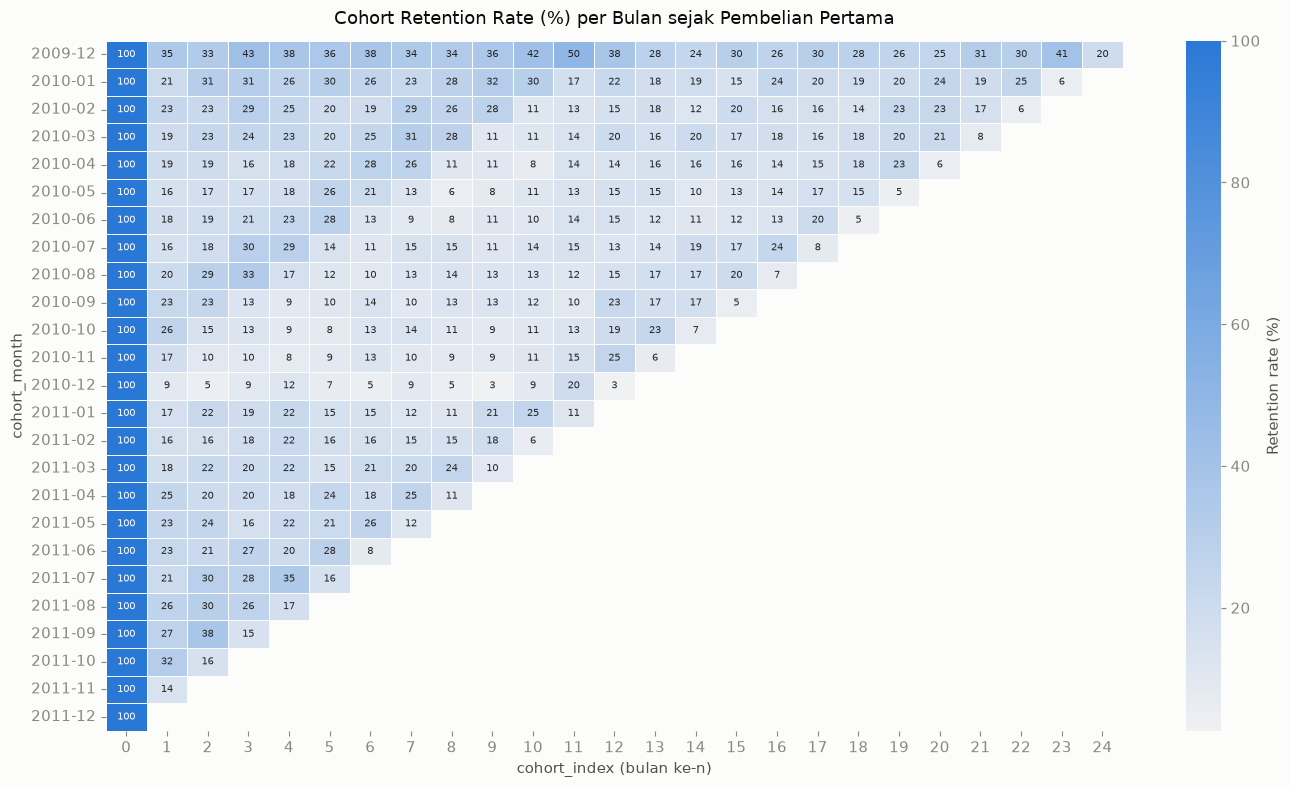

In [3]:
fig, ax = plt.subplots(figsize=(14, 8))
mask = cohort.isna()
sns.heatmap(
    cohort,
    mask=mask,
    annot=True,
    fmt=".0f",
    annot_kws={"size": 7},
    cmap=sns.light_palette(WARNA_BIRU, as_cmap=True),
    linewidths=0.5,
    linecolor=WARNA_SURFACE,
    cbar_kws={"label": "Retention rate (%)"},
    ax=ax,
)
ax.set_title("Cohort Retention Rate (%) per Bulan sejak Pembelian Pertama", fontsize=13, pad=12)
ax.set_xlabel("cohort_index (bulan ke-n)")
ax.set_ylabel("cohort_month")
plt.tight_layout()
plt.show()


## 3. Distribusi Segment RFM

**Insight:** *Hibernating* adalah segmen terbesar (1.515 customer, 25.85%
dari total) — lebih dari seperempat customer sudah lama tidak belanja &
frequency-nya rendah. *Loyal Customers* (1.157, 19.74%) dan *Champions*
(830, 14.16%) melengkapi tiga besar.

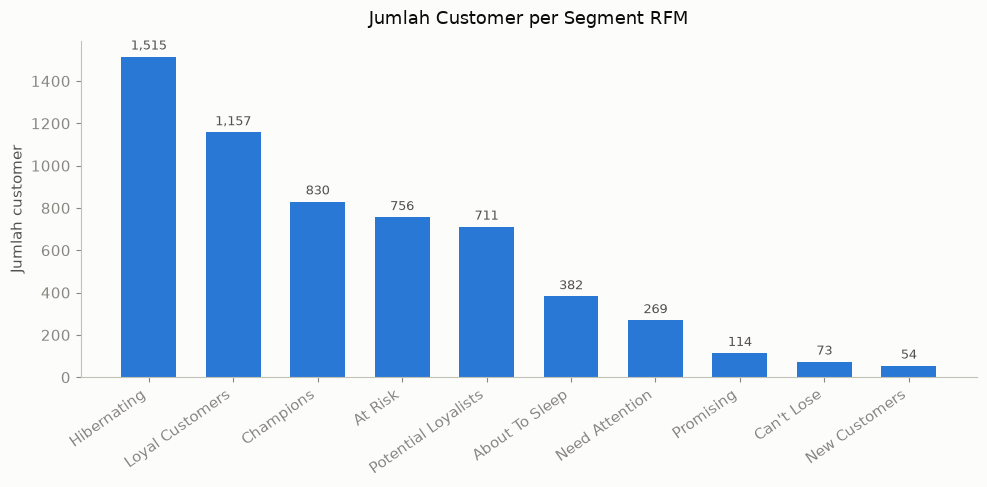

In [4]:
jumlah_per_segmen = rfm["Segment"].value_counts()

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(jumlah_per_segmen.index, jumlah_per_segmen.values, color=WARNA_BIRU, width=0.65)
ax.bar_label(bars, labels=[f"{v:,}" for v in jumlah_per_segmen.values], padding=3, fontsize=9, color=WARNA_INK_SEKUNDER)
ax.set_ylabel("Jumlah customer")
ax.set_title("Jumlah Customer per Segment RFM", fontsize=13, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", rotation=35)
for label in ax.get_xticklabels():
    label.set_ha("right")
plt.tight_layout()
plt.show()


**Kontribusi Monetary per segmen** (jumlah customer vs nilainya buat
bisnis — ini yang bikin kontras *Champions* vs *Hibernating* kelihatan
jelas): *Champions* cuma 14.16% dari jumlah customer tapi menyumbang
**51.52%** dari total Monetary. *Hibernating* justru sebaliknya — 25.85%
dari jumlah customer (segmen terbesar) tapi cuma menyumbang **3.62%** dari
total Monetary. Pola 80/20 klasik: segmen kecil bernilai tinggi jauh lebih
penting buat revenue daripada segmen besar bernilai rendah.

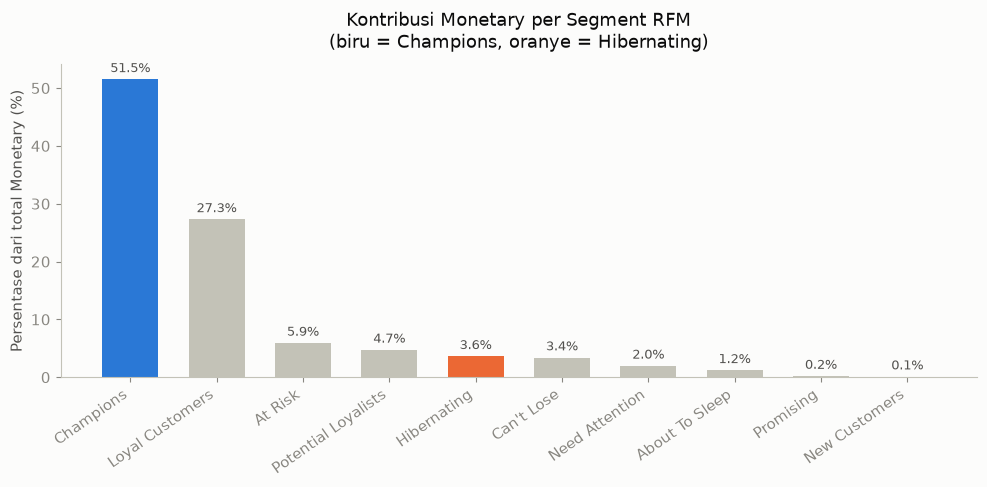

In [5]:
persen_monetary_per_segmen = (
    rfm.groupby("Segment")["Monetary"].sum() / rfm["Monetary"].sum() * 100
).sort_values(ascending=False)

warna_bar = [
    WARNA_BIRU if segmen == "Champions"
    else WARNA_ORANYE if segmen == "Hibernating"
    else WARNA_BASELINE
    for segmen in persen_monetary_per_segmen.index
]

fig, ax = plt.subplots(figsize=(10, 5))
bars = ax.bar(persen_monetary_per_segmen.index, persen_monetary_per_segmen.values, color=warna_bar, width=0.65)
ax.bar_label(bars, labels=[f"{v:.1f}%" for v in persen_monetary_per_segmen.values], padding=3, fontsize=9, color=WARNA_INK_SEKUNDER)
ax.set_ylabel("Persentase dari total Monetary (%)")
ax.set_title("Kontribusi Monetary per Segment RFM\n(biru = Champions, oranye = Hibernating)", fontsize=13, pad=12)
ax.spines[["top", "right"]].set_visible(False)
ax.tick_params(axis="x", rotation=35)
for label in ax.get_xticklabels():
    label.set_ha("right")
plt.tight_layout()
plt.show()


## 4. Average Order Value: Churned vs Active

Uji-t Welch di `04_churn_geo.py` (asumsi varians tidak sama) membandingkan
rata-rata Average Order Value antara customer Churned (Recency > ambang
churn) dan Active: rata-rata Churned 340.81 (n=2.387) vs Active 407.81
(n=3.474), t = -2.36, p = 0.018 (< 0.05) — **signifikan secara statistik**,
Active belanja dengan order value rata-rata lebih tinggi.

**Insight:** distribusi AverageOrderValue sangat *right-skewed* (banyak
outlier tinggi, sampai ~84 ribu), jadi outlier ekstrem disembunyikan dari
boxplot di bawah supaya box-nya tetap kebaca — garis putus-putus di dalam
tiap box menandai rata-rata grup (bukan median), sesuai yang diuji uji-t di
atas. Boxnya sendiri kelihatan tumpang-tindih banyak (median dua grup tidak
jauh beda), jadi selisih rata-rata yang signifikan itu lebih didorong oleh
ekor kanan (customer bernilai tinggi) yang lebih tebal di grup Active,
bukan oleh customer tipikalnya yang jauh berbeda.

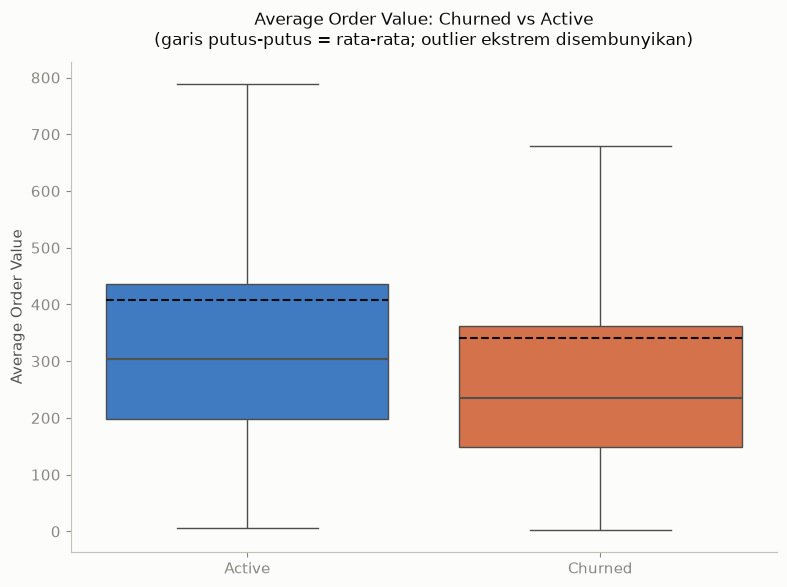

In [6]:
urutan_status = ["Active", "Churned"]

fig, ax = plt.subplots(figsize=(8, 6))
sns.boxplot(
    data=churn,
    x="ChurnStatus",
    y="AverageOrderValue",
    order=urutan_status,
    hue="ChurnStatus",
    hue_order=urutan_status,
    palette={"Active": WARNA_BIRU, "Churned": WARNA_ORANYE},
    legend=False,
    showfliers=False,
    showmeans=True,
    meanline=True,
    meanprops={"color": WARNA_INK_UTAMA, "linestyle": "--", "linewidth": 1.5},
    medianprops={"color": WARNA_INK_SEKUNDER, "linewidth": 1.5},
    ax=ax,
)
ax.set_ylabel("Average Order Value")
ax.set_xlabel("")
ax.set_title(
    "Average Order Value: Churned vs Active\n(garis putus-putus = rata-rata; outlier ekstrem disembunyikan)",
    fontsize=12, pad=12,
)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()
